# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Computer Vision Lab** | Reg No: 024 | Name: Prevesh Maryam

| Setting | Rule | My value |
|---|---|---|
| Random seed | last two digits (024) | **24** |
| HOG cell size | last digit 4 = even | **8 x 8** |
| SIFT grid | last digit 4 (0 to 4) | **4 x 4 grid (16 keypoints)** |

In [1]:
%pip install -q medmnist opencv-python scikit-learn scikit-image matplotlib pandas

## Personal Settings

In [2]:
REG_NO     = "024"
SEED       = 24          # last two digits
HOG_CELL   = (8, 8)      # last digit 4 = even
SIFT_GRID  = 4           # 4 x 4 grid = 16 keypoints (last digit 0-4)

CLASS_IDS   = [1, 5, 6, 7]   # eosinophil, monocyte, neutrophil, platelet
CLASS_NAMES = ["eosinophil", "monocyte", "neutrophil", "platelet"]
N_TRAIN, N_VAL, N_TEST = 100, 30, 30
IMG_SIZE    = 128
ROT_ANGLE   = 20
NOISE_SIGMA = 0.05
C_GRID      = [0.1, 1, 10]

print(f"Seed={SEED}, HOG cell={HOG_CELL}, SIFT grid={SIFT_GRID}x{SIFT_GRID} ({SIFT_GRID**2} keypoints)")

Seed=24, HOG cell=(8, 8), SIFT grid=4x4 (16 keypoints)


#  Data Setup

100%|██████████| 156M/156M [04:59<00:00, 522kB/s] 


Train | X shape: (400, 128, 128) | y shape: (400,) | counts: {'eosinophil': 100, 'monocyte': 100, 'neutrophil': 100, 'platelet': 100}
Val   | X shape: (120, 128, 128) | y shape: (120,) | counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}
Test  | X shape: (120, 128, 128) | y shape: (120,) | counts: {'eosinophil': 30, 'monocyte': 30, 'neutrophil': 30, 'platelet': 30}


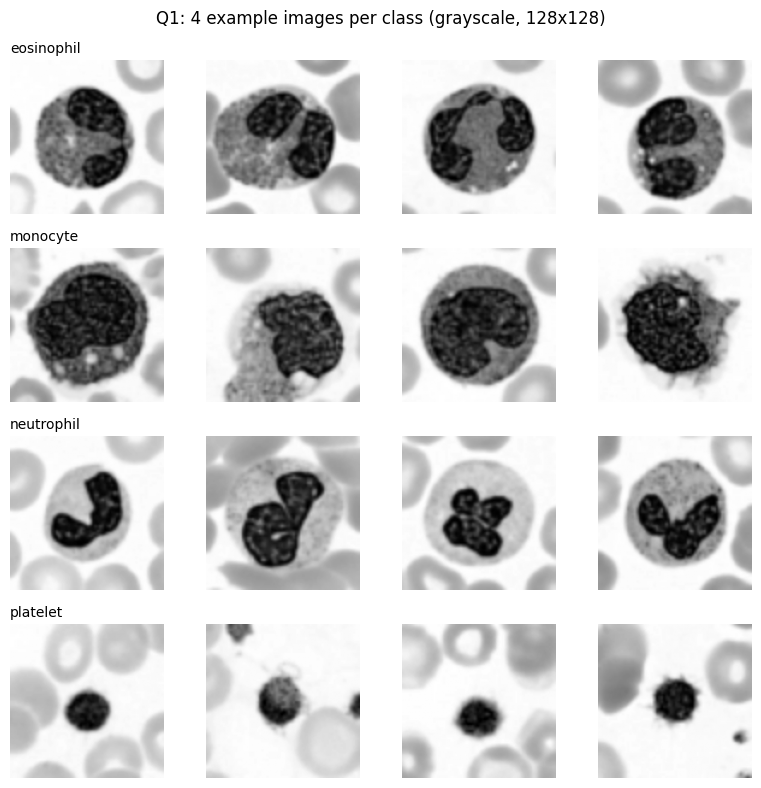

In [3]:
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(SEED)
ds = {s: BloodMNIST(split=s, download=True, size=64) for s in ["train", "val", "test"]}

def subset(dataset, n_per_class, seed):
    rng = np.random.RandomState(seed)
    X_all, y_all = dataset.imgs, dataset.labels.ravel()
    X_out, y_out = [], []
    for new_label, cid in enumerate(CLASS_IDS):
        idx = np.where(y_all == cid)[0]
        chosen = rng.choice(idx, n_per_class, replace=False)
        for i in chosen:
            g = cv2.cvtColor(X_all[i], cv2.COLOR_RGB2GRAY)
            g = cv2.resize(g, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
            X_out.append(g); y_out.append(new_label)
    return np.array(X_out, dtype=np.uint8), np.array(y_out)

X_train, y_train = subset(ds["train"], N_TRAIN, SEED)
X_val,   y_val   = subset(ds["val"],   N_VAL,   SEED)
X_test,  y_test  = subset(ds["test"],  N_TEST,  SEED)

for name, X, y in [("Train", X_train, y_train), ("Val", X_val, y_val), ("Test", X_test, y_test)]:
    counts = {CLASS_NAMES[k]: int((y == k).sum()) for k in range(4)}
    print(f"{name:5s} | X shape: {X.shape} | y shape: {y.shape} | counts: {counts}")

fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r in range(4):
    idxs = np.where(y_train == r)[0][:4]
    for c, i in enumerate(idxs):
        axes[r, c].imshow(X_train[i], cmap="gray"); axes[r, c].axis("off")
        if c == 0: axes[r, c].set_title(CLASS_NAMES[r], fontsize=10, loc="left")
plt.suptitle("Q1: 4 example images per class (grayscale, 128x128)")
plt.tight_layout(); plt.show()

HOG + SVM

### Feature length by hand
- Image = 128 x 128, cell = 8 x 8, so cells per side = 128 / 8 = **16**
- Block = 2 x 2 cells, stride = 1 cell, so blocks per side = 16 - 1 = **15**, total blocks = 15 x 15 = **225**
- Values per block = 2 x 2 cells x 9 orientations = **36**
- Total HOG length = 225 x 36 = **8100**

In [4]:
def hog_feat(img):
    return hog(img, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True)

def extract_hog(X): return np.array([hog_feat(im) for im in X])

Ftr_hog, Fva_hog = extract_hog(X_train), extract_hog(X_val)
print("HOG feature length:", Ftr_hog.shape[1], "| train:", Ftr_hog.shape, "| val:", Fva_hog.shape)
print("Hand calculation check: 15*15*2*2*9 =", 15*15*2*2*9)

HOG feature length: 8100 | train: (400, 8100) | val: (120, 8100)
Hand calculation check: 15*15*2*2*9 = 8100


### HOG picture (one image per class)

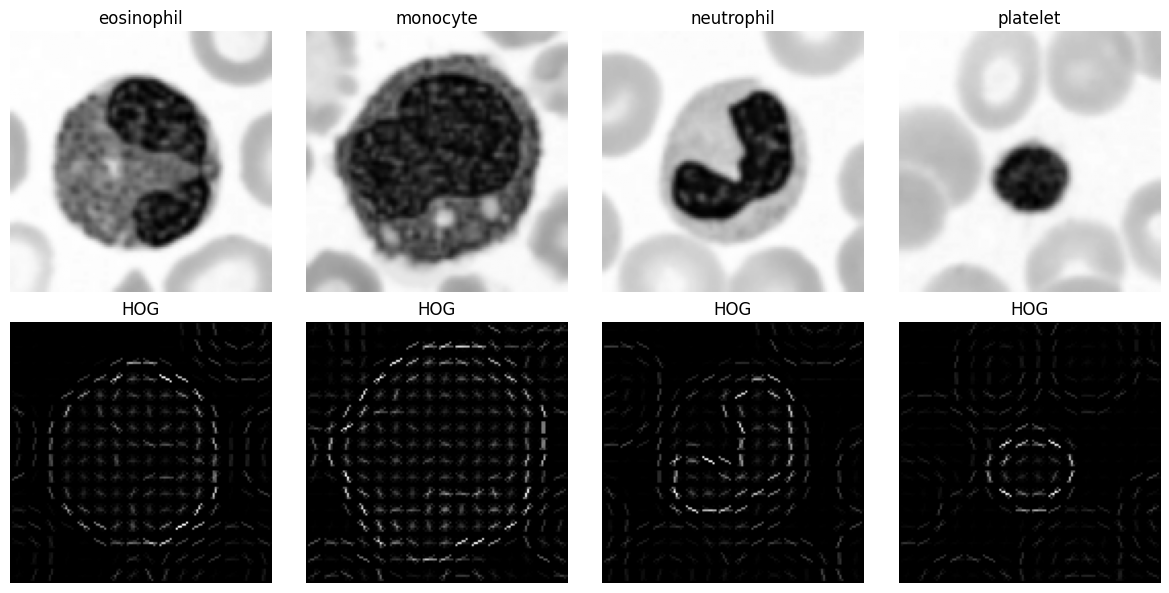

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for k in range(4):
    img = X_train[np.where(y_train == k)[0][0]]
    _, hog_img = hog(img, orientations=9, pixels_per_cell=HOG_CELL, cells_per_block=(2, 2),
                     block_norm="L2-Hys", visualize=True)
    axes[0, k].imshow(img, cmap="gray"); axes[0, k].set_title(CLASS_NAMES[k]); axes[0, k].axis("off")
    axes[1, k].imshow(hog_img, cmap="gray"); axes[1, k].set_title("HOG"); axes[1, k].axis("off")
plt.tight_layout(); plt.show()

### Train SVM (C chosen on validation)

--- HOG + SVM: C selection on validation ---
   C  val_acc
 0.1 0.725000
 1.0 0.716667
10.0 0.708333
HOG + SVM: best C=0.1 | val accuracy=0.7250 | val macro-F1=0.7267


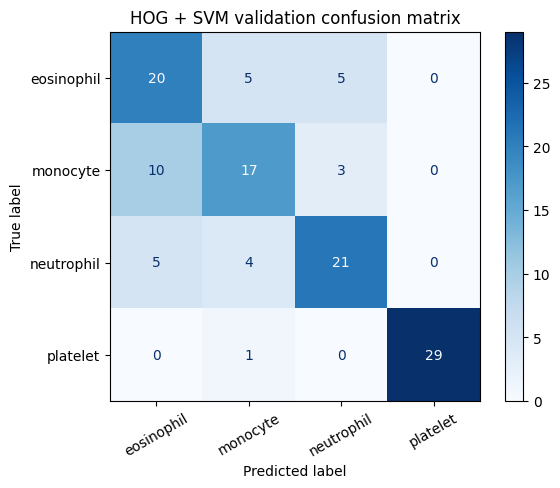

[[20  5  5  0]
 [10 17  3  0]
 [ 5  4 21  0]
 [ 0  1  0 29]]


In [6]:
def train_select(Ftr, ytr, Fva, yva, name):
    rows, best = [], (-1, None, None)
    for C in C_GRID:
        m = LinearSVC(C=C, max_iter=20000, random_state=SEED).fit(Ftr, ytr)
        acc = accuracy_score(yva, m.predict(Fva))
        rows.append({"C": C, "val_acc": acc})
        if acc > best[0]: best = (acc, C, m)      # ties: smaller C kept (first in grid)
    print(f"--- {name}: C selection on validation ---")
    print(pd.DataFrame(rows).to_string(index=False))
    acc, C, m = best
    pred = m.predict(Fva)
    f1 = f1_score(yva, pred, average="macro")
    cm = confusion_matrix(yva, pred)
    print(f"{name}: best C={C} | val accuracy={acc:.4f} | val macro-F1={f1:.4f}")
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", xticks_rotation=30)
    plt.title(f"{name} validation confusion matrix"); plt.show()
    print(cm)
    return m, C, cm

hog_model, hog_C, hog_cm = train_select(Ftr_hog, y_train, Fva_hog, y_val, "HOG + SVM")

# SIFT + SVM

###  Normal SIFT detection on training images

Average keypoints/image: 73.33
Min: 10 | Max: 294
Images with zero keypoints: 0 of 400


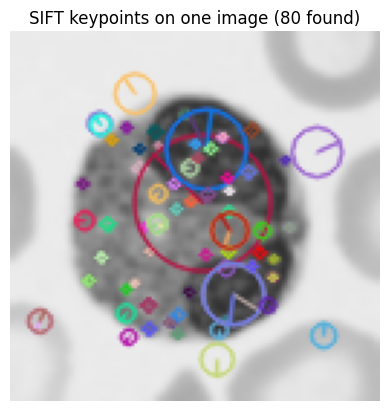

In [7]:
sift = cv2.SIFT_create()
kp_counts = []
for im in X_train:
    kps, _ = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)
print(f"Average keypoints/image: {kp_counts.mean():.2f}")
print(f"Min: {kp_counts.min()} | Max: {kp_counts.max()}")
print(f"Images with zero keypoints: {(kp_counts == 0).sum()} of {len(kp_counts)}")

img = X_train[0]
kps, _ = sift.detectAndCompute(img, None)
vis = cv2.drawKeypoints(img, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(vis, cmap="gray"); plt.title(f"SIFT keypoints on one image ({len(kps)} found)"); plt.axis("off"); plt.show()

**Why is a different number of keypoints a problem for an SVM?**
An SVM needs every sample to be a feature vector of the same fixed length. Each keypoint gives a 128-d descriptor, so an image with 10 keypoints and one with 50 give vectors of different sizes, and the SVM cannot compare them (some images may even have 0 keypoints).

### Fixed grid SIFT
Keypoints are placed on a regular 4 x 4 grid (cell centres at 16, 48, 80, 112), keypoint size = 32.

**Feature length by hand:** 4 x 4 = 16 grid points, each descriptor = 128 values, so 16 x 128 = **2048**.

Grid coordinates: [16.0, 48.0, 80.0, 112.0] | number of keypoints: 16
SIFT feature length: 2048 | train: (400, 2048) | val: (120, 2048)
Hand calculation check: 16*128 = 2048


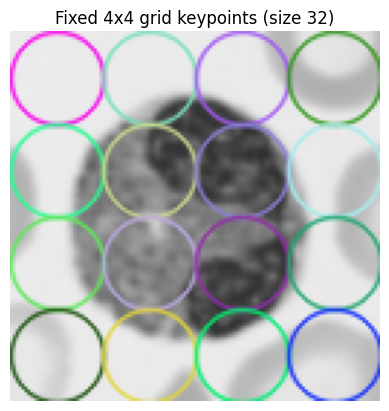

In [8]:
coords = [(i + 0.5) * IMG_SIZE / SIFT_GRID for i in range(SIFT_GRID)]   # 16, 48, 80, 112
grid_kps = [cv2.KeyPoint(float(x), float(y), 32) for y in coords for x in coords]
print("Grid coordinates:", coords, "| number of keypoints:", len(grid_kps))

def sift_feat(img):
    _, d = sift.compute(img, grid_kps)
    assert d is not None and d.shape == (SIFT_GRID**2, 128), f"bad descriptor shape {None if d is None else d.shape}"
    return d.flatten()

def extract_sift(X): return np.array([sift_feat(im) for im in X])

Ftr_sift, Fva_sift = extract_sift(X_train), extract_sift(X_val)
print("SIFT feature length:", Ftr_sift.shape[1], "| train:", Ftr_sift.shape, "| val:", Fva_sift.shape)
print("Hand calculation check: 16*128 =", 16 * 128)

vis = cv2.drawKeypoints(X_train[0], grid_kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(vis, cmap="gray"); plt.title("Fixed 4x4 grid keypoints (size 32)"); plt.axis("off"); plt.show()

### Train SVM (C chosen on validation)

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


--- SIFT + SVM: C selection on validation ---
   C  val_acc
 0.1 0.716667
 1.0 0.716667
10.0 0.716667
SIFT + SVM: best C=0.1 | val accuracy=0.7167 | val macro-F1=0.7249


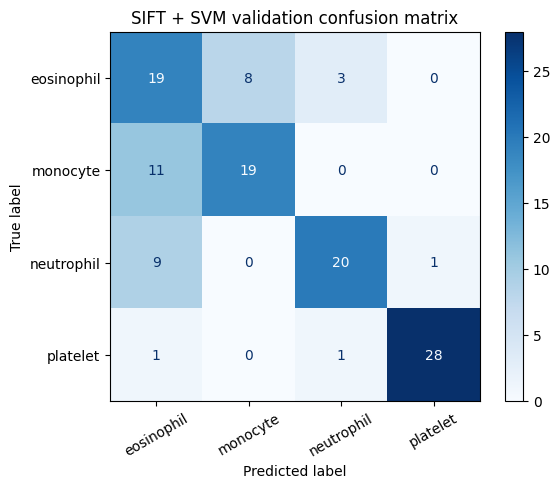

[[19  8  3  0]
 [11 19  0  0]
 [ 9  0 20  1]
 [ 1  0  1 28]]


In [9]:
sift_model, sift_C, sift_cm = train_select(Ftr_sift, y_train, Fva_sift, y_val, "SIFT + SVM")

# Robustness

### Prediction
- **Rotation:** I think **HOG** will lose more accuracy. HOG uses a fixed grid of cell-wise gradient histograms, so rotating by 20 degrees shifts the edge orientations into different bins and cells. The grid SIFT descriptor is also not rotation-invariant here (orientation is computed from the grid keypoint's angle, which is fixed at 0 and not re-estimated), but its 32 px support window with Gaussian weighting is smoother, so I expect it to be a bit more tolerant.
- **Noise:** I think **SIFT** will lose more accuracy. SIFT builds histograms from raw pixel gradients over only 16 locations, and noise adds random gradients that directly change those histograms. HOG averages over many cells and block-normalises, which damps noise.



### Evaluation on test set (models frozen, trained on train only)

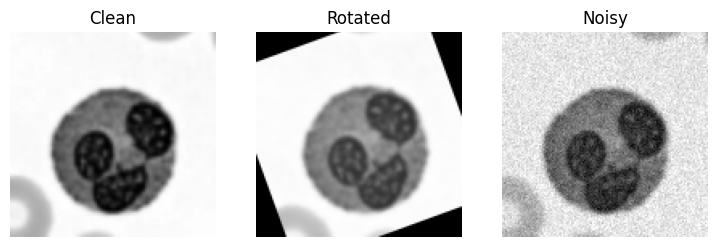

            Clean accuracy  Rotated accuracy  Noisy accuracy
HOG + SVM           0.6667            0.6333          0.5417
SIFT + SVM          0.7583            0.3000          0.7583

            Drop (rotation)  Drop (noise)
HOG + SVM            0.0333         0.125
SIFT + SVM           0.4583         0.000


In [10]:
def rotate_imgs(X, angle):
    M = cv2.getRotationMatrix2D((IMG_SIZE / 2, IMG_SIZE / 2), angle, 1.0)
    return np.array([cv2.warpAffine(im, M, (IMG_SIZE, IMG_SIZE), flags=cv2.INTER_LINEAR,
                                    borderMode=cv2.BORDER_CONSTANT, borderValue=0) for im in X])

def noisy_imgs(X, sigma, seed):
    rng = np.random.RandomState(seed)
    x = X.astype(np.float32) / 255.0                      # scale to 0..1
    x = np.clip(x + rng.normal(0, sigma, x.shape), 0, 1)
    return np.round(x * 255).astype(np.uint8)             # back to uint8 for HOG/SIFT

conditions = {"Clean": X_test,
              "Rotated": rotate_imgs(X_test, ROT_ANGLE),
              "Noisy": noisy_imgs(X_test, NOISE_SIGMA, SEED)}

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (n, Xc) in zip(axes, conditions.items()):
    ax.imshow(Xc[0], cmap="gray"); ax.set_title(n); ax.axis("off")
plt.show()

results, preds = {}, {}
for mname, model, feat in [("HOG + SVM", hog_model, extract_hog), ("SIFT + SVM", sift_model, extract_sift)]:
    results[mname] = {}
    for cname, Xc in conditions.items():
        p = model.predict(feat(Xc))
        preds[(mname, cname)] = p
        results[mname][cname] = accuracy_score(y_test, p)

tbl = pd.DataFrame(results).T[["Clean", "Rotated", "Noisy"]]
tbl.columns = ["Clean accuracy", "Rotated accuracy", "Noisy accuracy"]
print(tbl.round(4).to_string())
tbl["Drop (rotation)"] = tbl["Clean accuracy"] - tbl["Rotated accuracy"]
tbl["Drop (noise)"]    = tbl["Clean accuracy"] - tbl["Noisy accuracy"]
print()
print(tbl[["Drop (rotation)", "Drop (noise)"]].round(4).to_string())

### Was my prediction correct?

In [11]:
d = tbl
rot_worse   = d["Drop (rotation)"].idxmax()
noise_worse = d["Drop (noise)"].idxmax()
print(f"Rotation: {rot_worse} lost more accuracy "
      f"(HOG drop={d.loc['HOG + SVM','Drop (rotation)']:.4f}, SIFT drop={d.loc['SIFT + SVM','Drop (rotation)']:.4f}).")
print(f"Noise: {noise_worse} lost more accuracy "
      f"(HOG drop={d.loc['HOG + SVM','Drop (noise)']:.4f}, SIFT drop={d.loc['SIFT + SVM','Drop (noise)']:.4f}).")
print("My prediction -> rotation: HOG, noise: SIFT")
print("Rotation prediction correct?", rot_worse == "HOG + SVM")
print("Noise prediction correct?   ", noise_worse == "SIFT + SVM")

Rotation: SIFT + SVM lost more accuracy (HOG drop=0.0333, SIFT drop=0.4583).
Noise: HOG + SVM lost more accuracy (HOG drop=0.1250, SIFT drop=0.0000).
My prediction -> rotation: HOG, noise: SIFT
Rotation prediction correct? False
Noise prediction correct?    False


#  Short Answers and AI Log

### Q5(a) Why does HOG use block normalisation?
Gradient magnitudes change with lighting and contrast, so raw cell histograms for the same cell structure can differ a lot between images. Block normalisation divides each block's histogram by its own norm (L2-Hys here), which makes the features much less sensitive to illumination and contrast changes. Overlapping blocks also let each cell be normalised in several contexts, which improves stability.

### Q5(b) Why is it wrong to choose C using the test set?
The test set must stay unseen so that it gives an honest estimate of performance on new data. If C is picked to maximise test accuracy, information from the test set leaks into the model choice, so the reported accuracy becomes optimistically biased. C should be chosen on the validation set, and the test set used only once at the end (Q4).

### Q5(c) Most confused classes

In [12]:
def top_confusion(cm):
    c = cm.copy().astype(int); np.fill_diagonal(c, 0)
    i, j = np.unravel_index(c.argmax(), c.shape)
    return CLASS_NAMES[i], CLASS_NAMES[j], c[i, j], c[j, i]

for name, cm in [("HOG + SVM", hog_cm), ("SIFT + SVM", sift_cm)]:
    a, b, n1, n2 = top_confusion(cm)
    print(f"{name} (validation): most confused = {a} vs {b} | {a}->{b}: {n1}, {b}->{a}: {n2}")

# same check on the clean test set
for name in ["HOG + SVM", "SIFT + SVM"]:
    cm = confusion_matrix(y_test, preds[(name, "Clean")])
    a, b, n1, n2 = top_confusion(cm)
    print(f"{name} (clean test): most confused = {a} vs {b} | {a}->{b}: {n1}, {b}->{a}: {n2}")

HOG + SVM (validation): most confused = monocyte vs eosinophil | monocyte->eosinophil: 10, eosinophil->monocyte: 5
SIFT + SVM (validation): most confused = monocyte vs eosinophil | monocyte->eosinophil: 11, eosinophil->monocyte: 8
HOG + SVM (clean test): most confused = neutrophil vs eosinophil | neutrophil->eosinophil: 12, eosinophil->neutrophil: 5
SIFT + SVM (clean test): most confused = eosinophil vs monocyte | eosinophil->monocyte: 9, monocyte->eosinophil: 6


**Answer:** (fill the two class names from the printed output above). Eosinophils and neutrophils are the classic pair: both are granulocytes with a lobed nucleus and similar size. In colour images the eosinophil is separated mainly by its bright red-orange granules, but grayscale conversion collapses colour into one intensity channel, so this cue is lost and only texture/shape remain, which look alike.

